# Customer Churn Analysis & Prediction — Telecommunications

**Objective.** Understand which customer attributes are associated with churn, and build a classification model that flags customers at elevated risk of leaving, so the retention team can prioritise outreach.

**Dataset.** IBM Telco Customer Churn sample dataset (public; see README for source and attribution). Target: `Churn` (Yes/No).

**How to read this notebook.** Every phase explains *why* a step is done, then shows the code, then interprets the real output. Two rules apply throughout:
- **Correlation is not causation.** Everything below describes *associations* in a historical sample. It cannot prove that changing one factor (e.g. contract type) would cause customers to stay.
- **No leakage.** All fitting (scaling, encoding, tuning) happens on training data only, inside scikit-learn Pipelines. The test set is used once, for final evaluation.

**Contents:** 1 Data understanding · 2 Cleaning · 3 EDA · 4 Visualisation · 5 Preprocessing · 6 Modeling · 7 Evaluation · 8 Interpretation · 9 Business recommendations · 10 Deliverables

In [1]:
import sys, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import churn_utils as cu

DATA_RAW = ROOT / "data" / "raw" / "Telco-Customer-Churn.csv"
DATA_CLEAN = ROOT / "data" / "processed" / "telco_churn_cleaned.csv"
FIG_DIR = ROOT / "outputs" / "visualizations"; FIG_DIR.mkdir(parents=True, exist_ok=True); DATA_CLEAN.parent.mkdir(parents=True, exist_ok=True)
MODEL_DIR = ROOT / "models"; MODEL_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"No": "#4C72B0", "Yes": "#C44E52"}   # blue = stayed, red = churned
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 160)

def save_fig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

---
## Phase 1 — Data Understanding
**Purpose:** inspect the raw file *before* changing anything, so every later cleaning decision is traceable to a documented finding.

In [2]:
raw = pd.read_csv(DATA_RAW)           # raw file is never overwritten
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
display(raw.head())
display(raw.tail())

Rows: 7,043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


**Finding.** The file has the expected structure (7,043 customers × 21 columns). Each row is one customer; `customerID` is an identifier, `Churn` is the target.

In [3]:
info = pd.DataFrame({"dtype": raw.dtypes.astype(str), "n_unique": raw.nunique(), "n_missing": raw.isna().sum(),
                     "example": raw.iloc[0]})
display(info)

,dtype,n_unique,n_missing,example
customerID,str,7043,0,7590-VHVEG
gender,str,2,0,Female
SeniorCitizen,int64,2,0,0
Partner,str,2,0,Yes
Dependents,str,2,0,No
tenure,int64,73,0,1
PhoneService,str,2,0,No
MultipleLines,str,3,0,No phone service
InternetService,str,3,0,DSL
OnlineSecurity,str,3,0,No


In [4]:
target = "Churn"
id_col = "customerID"
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]   # TotalCharges is text in the raw file (see below)
binary_flag = ["SeniorCitizen"]                                 # stored as 0/1 integers but is categorical in meaning
categorical_cols = [c for c in raw.columns if c not in numeric_cols + binary_flag + [id_col, target]]
print("Numerical  :", numeric_cols)
print("Binary 0/1 :", binary_flag)
print("Categorical:", categorical_cols)

Numerical  : ['tenure', 'MonthlyCharges', 'TotalCharges']
Binary 0/1 : ['SeniorCitizen']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


**Finding — feature types.** Three genuinely numerical features (`tenure` in months, `MonthlyCharges`, `TotalCharges`), one 0/1 flag (`SeniorCitizen`), and 16 categorical features. Note that pandas reads `TotalCharges` as **text (`object`/`str`)**, not as a number — this is the first data-quality issue.

In [5]:
display(raw[["tenure", "MonthlyCharges", "SeniorCitizen"]].describe().T)
print("Missing values (NaN):", int(raw.isna().sum().sum()))
print("Fully duplicated rows:", raw.duplicated().sum(), "| duplicated customerIDs:", raw[id_col].duplicated().sum())
blank_tc = raw[raw["TotalCharges"].str.strip() == ""]
print(f"\nBlank-string TotalCharges: {len(blank_tc)}")
display(blank_tc[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00


Missing values (NaN): 0
Fully duplicated rows: 0 | duplicated customerIDs: 0

Blank-string TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Findings — data quality (before any modification)**
1. **No NaN values and no duplicates** (rows or customer IDs).
2. **`TotalCharges` hides 11 blank strings.** Pandas does not count them as missing, which is why `isna()` reports zero. They block numeric conversion.
3. **All 11 blank rows have `tenure = 0`** and none has churned: these are brand-new customers who have not yet completed a billing cycle, so no total has been billed. This is a systematic, explainable gap — not random missingness.
4. `SeniorCitizen` is coded 0/1 while all other flags are Yes/No text (inconsistent encoding, harmless but noted).
5. Several service columns contain `"No internet service"` / `"No phone service"` as a third category. These are *structurally implied* by `InternetService` / `PhoneService`, not errors (checked below).

In [6]:
for c in categorical_cols:
    print(f"{c:18s}", sorted(raw[c].unique()))

gender             ['Female', 'Male']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']


**Finding.** Category labels are clean and consistent (no spelling variants or stray capitalisation). The `"No internet service"` label appears in exactly the six internet add-on columns, and `"No phone service"` only in `MultipleLines` — consistent with the 1,526 customers without internet and 682 without phone service.

---
## Phase 2 — Data Cleaning
**Purpose:** fix only what is demonstrably wrong, justify each decision, and keep the raw data untouched (we work on a copy).

In [7]:
df, clean_log = cu.clean_data(raw)     # works on a copy; `raw` is unchanged
print(clean_log)
print("TotalCharges dtype now:", df["TotalCharges"].dtype, "| NaN remaining:", df["TotalCharges"].isna().sum())
assert raw["TotalCharges"].dtype != df["TotalCharges"].dtype  # raw preserved as text

{'blank_total_charges': 11, 'blank_rows_all_tenure_zero': True, 'duplicate_rows': 0, 'duplicate_ids': 0}
TotalCharges dtype now: float64 | NaN remaining: 0


**Cleaning decisions**
| Issue | Decision | Why |
|---|---|---|
| `TotalCharges` stored as text | Converted to float | Needed for arithmetic and modeling |
| 11 blank `TotalCharges` (all `tenure = 0`) | Set to **0.0**; rows **kept** | A customer who has not completed a billing cycle has been billed nothing. Median/mean imputation (~$1,400–2,300) would invent charges that never occurred; dropping rows would discard 11 valid customers. |
| Duplicates | None found, nothing removed | — |
| `"No internet service"` / `"No phone service"` | Kept as-is | Structural, informative categories — `No internet service` customers churn at only 7.4%, so merging them with `No` would destroy signal |
| Outliers | Checked (below); none removed | See below |

IQR-rule outliers: {'tenure': 0, 'MonthlyCharges': 0, 'TotalCharges': 0}
Negative values  : {'tenure': 0, 'MonthlyCharges': 0, 'TotalCharges': 0}
tenure range: 0 - 72 | MonthlyCharges range: 18.25 - 118.75

TotalCharges - tenure*MonthlyCharges: median 0.0 | 5th-95th pct: [-112.5, 112.7]


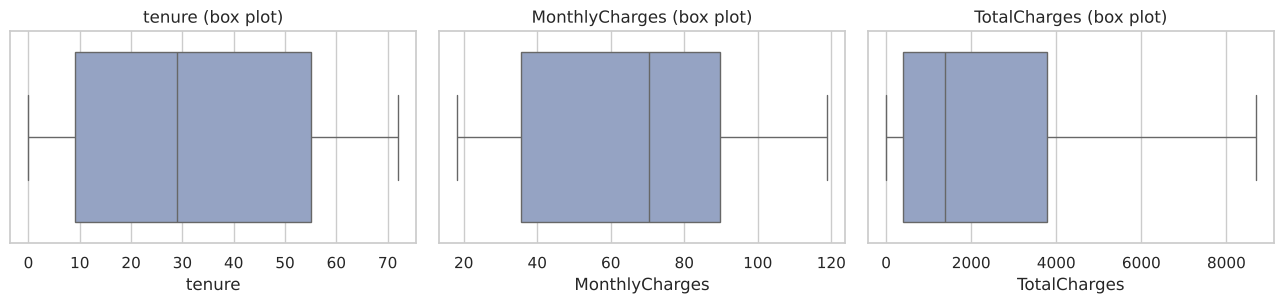

In [8]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

print("IQR-rule outliers:", {c: iqr_outliers(df[c]) for c in numeric_cols})
print("Negative values  :", {c: int((df[c] < 0).sum()) for c in numeric_cols})
print("tenure range:", df.tenure.min(), "-", df.tenure.max(), "| MonthlyCharges range:", df.MonthlyCharges.min(), "-", df.MonthlyCharges.max())

# Consistency: TotalCharges should be roughly tenure x MonthlyCharges (prices can change over time)
gap = (df["TotalCharges"] - df["tenure"] * df["MonthlyCharges"])
print("\nTotalCharges - tenure*MonthlyCharges: median", round(gap.median(), 2), "| 5th-95th pct:", gap.quantile([.05, .95]).round(1).tolist())
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, c in zip(ax, numeric_cols):
    sns.boxplot(x=df[c], ax=a, color="#8da0cb"); a.set_title(f"{c} (box plot)"); a.set_xlabel(c)
save_fig("outlier_boxplots")

**Finding — outliers.** The IQR rule flags **zero** outliers in all three numeric columns; values fall in plausible ranges (tenure 0–72 months, monthly charges \$18.25–\$118.75, no negatives). Large `TotalCharges` simply belong to long-tenure customers. Nothing is removed. The gap between `TotalCharges` and `tenure × MonthlyCharges` is non-zero for many customers, which is expected if plans or prices changed during the relationship; it is not treated as an error.

In [9]:
cleaned = df.copy()
cleaned["Churn_flag"] = (cleaned["Churn"] == "Yes").astype(int)
cleaned.to_csv(DATA_CLEAN, index=False)
print("Saved cleaned dataset:", DATA_CLEAN.name, cleaned.shape)

Saved cleaned dataset: telco_churn_cleaned.csv (7043, 22)


---
## Phase 3 — Exploratory Data Analysis
**Purpose:** quantify how churn varies across customer groups. We use *churn rate* = share of customers in a group who churned. All statements are **associations**.

In [10]:
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)
n_total = len(df); n_churn = int(df["Churn_flag"].sum())
overall = df["Churn_flag"].mean()
print(f"Churned: {n_churn:,} of {n_total:,} customers = {overall:.2%}   |   Retained: {n_total-n_churn:,} ({1-overall:.2%})")
print(f"Monthly recurring revenue of churned customers: ${df.loc[df.Churn_flag==1,'MonthlyCharges'].sum():,.0f} "
      f"({df.loc[df.Churn_flag==1,'MonthlyCharges'].sum()/df['MonthlyCharges'].sum():.1%} of all MRR in the file)")
display(df.groupby("Churn")[numeric_cols].agg(["mean", "median"]).round(1))

Churned: 1,869 of 7,043 customers = 26.54%   |   Retained: 5,174 (73.46%)
Monthly recurring revenue of churned customers: $139,131 (30.5% of all MRR in the file)


tenure        MonthlyCharges        TotalCharges        
        mean median           mean median         mean  median
Churn                                                         
No      37.6   38.0           61.3   64.4       2549.9  1679.5
Yes     18.0   10.0           74.4   79.6       1531.8   703.6

In [11]:
def rate_table(col, order=None):
    t = df.groupby(col)["Churn_flag"].agg(churn_rate="mean", customers="size", churned="sum")
    t["churn_rate"] = (t["churn_rate"] * 100).round(1)
    return t.loc[order] if order else t.sort_values("churn_rate", ascending=False)

df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
for col in ["Contract", "TenureGroup", "PaymentMethod", "InternetService", "SeniorCitizen", "gender", "Partner", "Dependents",
            "PaperlessBilling", "PhoneService", "MultipleLines"]:
    print(f"\n== Churn rate (%) by {col}"); display(rate_table(col))


== Churn rate (%) by Contract


,churn_rate,customers,churned
Contract,,,
Month-to-month,42.7,3875,1655
One year,11.3,1473,166
Two year,2.8,1695,48



== Churn rate (%) by TenureGroup


,churn_rate,customers,churned
TenureGroup,,,
0-12,47.4,2186,1037
13-24,28.7,1024,294
25-48,20.4,1594,325
49-72,9.5,2239,213



== Churn rate (%) by PaymentMethod


,churn_rate,customers,churned
PaymentMethod,,,
Electronic check,45.3,2365,1071
Mailed check,19.1,1612,308
Bank transfer (automatic),16.7,1544,258
Credit card (automatic),15.2,1522,232


... (12 outputs left out)


== Churn rate (%) by PhoneService


,churn_rate,customers,churned
PhoneService,,,
Yes,26.7,6361,1699
No,24.9,682,170



== Churn rate (%) by MultipleLines


,churn_rate,customers,churned
MultipleLines,,,
Yes,28.6,2971,850
No,25.0,3390,849
No phone service,24.9,682,170


In [12]:
service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
rows = []
for c in service_cols:
    for lvl in ["Yes", "No"]:
        s = df[df[c] == lvl]
        rows.append({"service": c, "subscribed": lvl, "customers": len(s), "churn_rate_%": round(s.Churn_flag.mean()*100, 1)})
svc = pd.DataFrame(rows).pivot(index="service", columns="subscribed", values="churn_rate_%")
svc["gap_pts (No - Yes)"] = (svc["No"] - svc["Yes"]).round(1)
print("Churn rate (%) among customers WITH internet service, by add-on subscription:")
display(svc.sort_values("gap_pts (No - Yes)", ascending=False))

Churn rate (%) among customers WITH internet service, by add-on subscription:


subscribed,No,Yes,gap_pts (No - Yes)
service,,,
OnlineSecurity,41.8,14.6,27.2
TechSupport,41.6,15.2,26.4
OnlineBackup,39.9,21.5,18.4
DeviceProtection,39.1,22.5,16.6
StreamingMovies,33.7,29.9,3.8
StreamingTV,33.5,30.1,3.4


**EDA findings (all from the output above)**
- **Overall churn: 1,869 of 7,043 customers (26.5%)** → the target is moderately imbalanced (about 1 churner per 3 retained).
- **Contract is the strongest single split:** month-to-month **42.7%** vs one-year **11.3%** vs two-year **2.8%**.
- **Tenure:** churn falls steadily with tenure — **47.4%** in the first 12 months vs **9.5%** after 48 months. Median tenure is 10 months for churners vs 38 for retained customers.
- **Payment method:** electronic check **45.3%**, versus 15.2–19.1% for the other three methods.
- **Internet service:** fiber optic **41.9%**, DSL 19.0%, no internet 7.4%.
- **Monthly charges:** churners pay more on average (\$74.44 mean vs \$61.27).
- **Support/protection add-ons:** among internet customers, those *without* Online Security (41.8% vs 14.6%) or Tech Support (41.6% vs 15.2%) churn far more. Streaming add-ons show only a 3–4 point difference.
- **Demographics:** seniors churn at 41.7% vs 23.6%; customers without a partner (33.0% vs 19.7%) or dependents (31.3% vs 15.5%) churn more. **Gender shows essentially no difference** (26.9% vs 26.2%). Phone service itself shows little difference (24.9% vs 26.7%).
- **Paperless billing:** 33.6% vs 16.3% for paper billing.

⚠️ **Caution — these factors overlap.** Fiber customers are more likely to be on month-to-month contracts and electronic check, so some of the "fiber effect" may really be a contract or price effect. We examine this with a Contract × Internet cross-tab below, and the model (Phase 8) helps separate overlapping effects, though still without proving causation.

In [13]:
ct = df.pivot_table(index="Contract", columns="InternetService", values="Churn_flag", aggfunc="mean").mul(100).round(1)
cnt = df.pivot_table(index="Contract", columns="InternetService", values="Churn_flag", aggfunc="size")
print("Churn rate (%) | Contract x InternetService"); display(ct)
print("Customers in each cell"); display(cnt)

Churn rate (%) | Contract x InternetService


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.2,54.6,18.9
One year,9.3,19.3,2.5
Two year,1.9,7.2,0.8


Customers in each cell


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,1223,2128,524
One year,570,539,364
Two year,628,429,638


**Finding.** Within every contract type, fiber customers still churn more than DSL customers (month-to-month: **54.6% vs 32.2%**; one-year 19.3% vs 9.3%; two-year 7.2% vs 1.9%). So fiber's higher churn is **not just** a contract effect — but the cause (price, service quality, competitor offers, customer type) cannot be determined from this dataset. The highest-risk segment is **month-to-month fiber customers: 54.6% churn across 2,128 customers.**

---
## Phase 4 — Data Visualisation
Each chart has a title, labelled axes, a legend where needed, an interpretation and a business insight. Colours: **blue = stayed, red = churned**. Figures are saved to `outputs/visualizations/`.

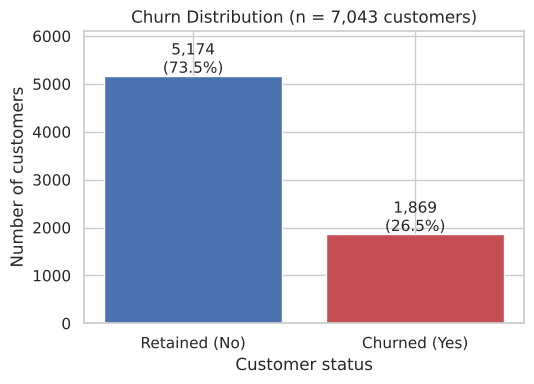

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 4))
counts = df["Churn"].value_counts().reindex(["No", "Yes"])
bars = ax.bar(["Retained (No)", "Churned (Yes)"], counts.values, color=[PALETTE["No"], PALETTE["Yes"]])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v + 60, f"{v:,}\n({v/len(df):.1%})", ha="center", fontsize=11)
ax.set_title("Churn Distribution (n = 7,043 customers)"); ax.set_ylabel("Number of customers"); ax.set_xlabel("Customer status")
ax.set_ylim(0, counts.max() * 1.18)
save_fig("01_churn_distribution")

**Interpretation.** 26.5% of customers (1,869) churned; 73.5% stayed. **Business insight:** roughly one in four customers in this file has left — a material loss. Because the classes are imbalanced (≈ 2.8 : 1), *accuracy alone is misleading*: a model that predicts "no churn" for everyone would score 73.5% accuracy while catching zero churners. This is why we evaluate with recall, precision, F1 and ROC-AUC.

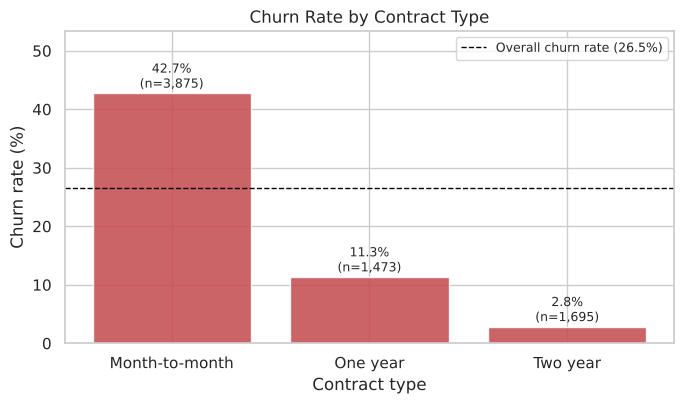

In [15]:
def churn_rate_bar(col, title, order=None, xlabel=None, fname=None, rotate=0, ax=None, show=True):
    t = rate_table(col, order) if order else rate_table(col)
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(7, 4.2))
    bars = ax.bar(t.index.astype(str), t["churn_rate"], color="#C44E52", alpha=.88)
    for b, (r, n) in zip(bars, zip(t["churn_rate"], t["customers"])):
        ax.text(b.get_x()+b.get_width()/2, r+1, f"{r:.1f}%\n(n={n:,})", ha="center", fontsize=9)
    ax.axhline(overall*100, color="black", ls="--", lw=1, label=f"Overall churn rate ({overall:.1%})")
    ax.set_title(title); ax.set_ylabel("Churn rate (%)"); ax.set_xlabel(xlabel or col)
    ax.set_ylim(0, t["churn_rate"].max()*1.25); ax.legend(loc="upper right", fontsize=9)
    ax.tick_params(axis="x", rotation=rotate)
    if own: save_fig(fname)

churn_rate_bar("Contract", "Churn Rate by Contract Type", ["Month-to-month", "One year", "Two year"], "Contract type", "02_churn_by_contract")

**Interpretation.** Month-to-month customers churn at **42.7%**, about **15×** the two-year rate (2.8%) and nearly 4× the one-year rate (11.3%). **Business insight:** 3,875 of 7,043 customers (55%) are month-to-month, and they account for **1,655 of the 1,869 churners (88.6%)**. Contract commitment is strongly *associated* with retention — but customers who choose long contracts may already be more loyal, so this is not proof that forcing a contract would reduce churn.

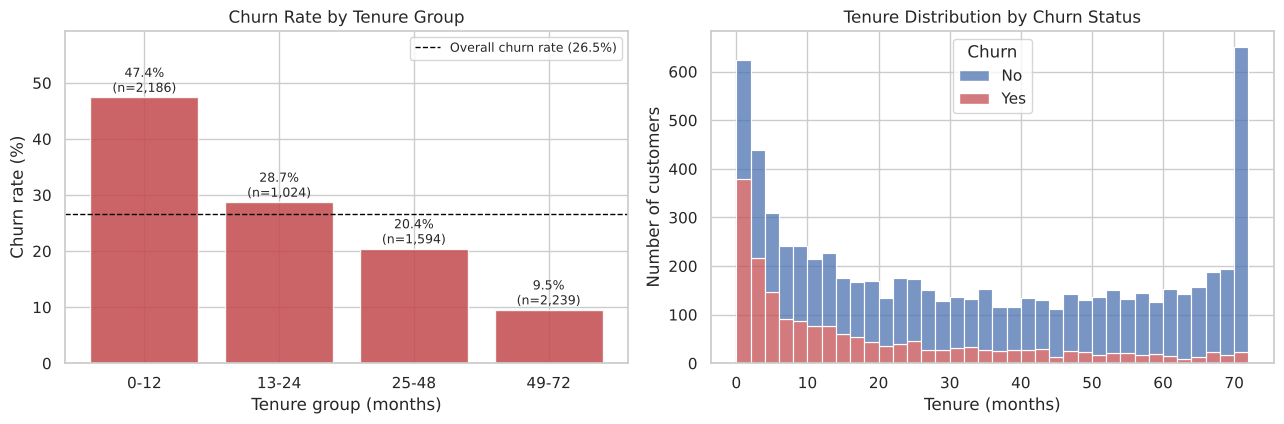

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
churn_rate_bar("TenureGroup", "Churn Rate by Tenure Group", ["0-12", "13-24", "25-48", "49-72"], "Tenure group (months)", ax=ax[0])
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, palette=PALETTE, multiple="stack", ax=ax[1])
ax[1].set_title("Tenure Distribution by Churn Status"); ax[1].set_xlabel("Tenure (months)"); ax[1].set_ylabel("Number of customers")
save_fig("03_churn_by_tenure")

**Interpretation.** Churn is highest in the first year (**47.4%**) and falls monotonically to **9.5%** beyond four years. The histogram shows a large cluster of churners in the first few months, while retained customers also include a large group of very long-tenure customers. **Business insight:** the first 12 months are the critical window — 2,186 customers sit in this group and nearly half leave. Early-life onboarding and engagement offers deserve the most attention.

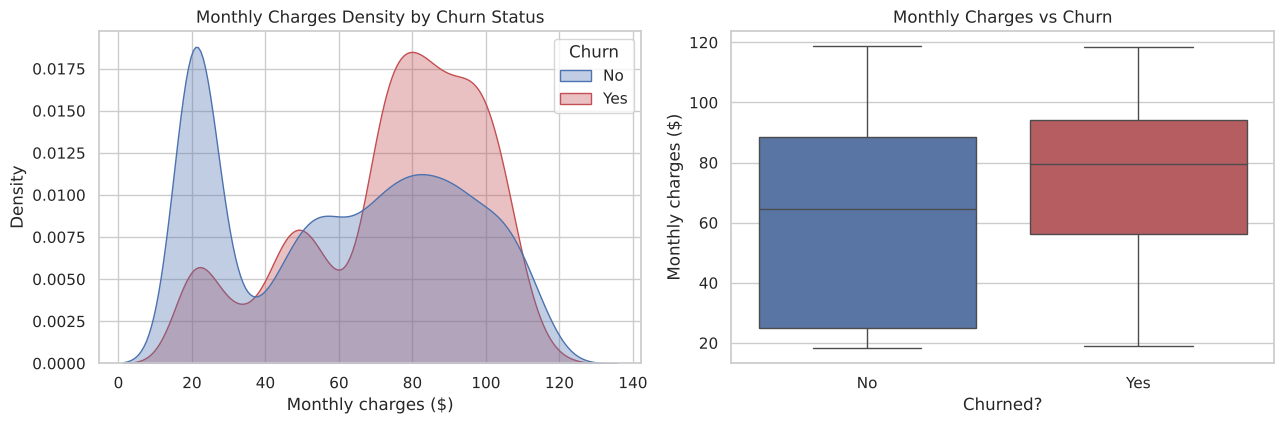

Churn rate (%) by monthly-charge band:


,churn_rate_%,customers
MonthlyCharges,,
"(0, 30]",9.8,1653
"(30, 50]",30.8,646
"(50, 70]",20.8,1161
"(70, 90]",37.8,1844
"(90, 120]",32.8,1739


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", palette=PALETTE, fill=True, common_norm=False, alpha=.35, ax=ax[0])
ax[0].set_title("Monthly Charges Density by Churn Status"); ax[0].set_xlabel("Monthly charges ($)"); ax[0].set_ylabel("Density")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=PALETTE, order=["No", "Yes"], ax=ax[1])
ax[1].set_title("Monthly Charges vs Churn"); ax[1].set_xlabel("Churned?"); ax[1].set_ylabel("Monthly charges ($)")
save_fig("04_monthly_charges_vs_churn")
bins = pd.cut(df["MonthlyCharges"], [0, 30, 50, 70, 90, 120])
print("Churn rate (%) by monthly-charge band:"); display((df.groupby(bins)["Churn_flag"].agg(["mean", "size"]).assign(mean=lambda d: (d["mean"]*100).round(1))).rename(columns={"mean":"churn_rate_%","size":"customers"}))

**Interpretation.** Retained customers show a spike at the low end (about \$20; 1,653 customers pay \$30 or less and only 9.8% of them churn), while churners are concentrated at higher charges: the 70–90 band has the highest churn (37.8%). Median monthly charge is **\$79.65 for churners vs \$64.43 for retained**. **Business insight:** higher-paying customers are leaving. Because higher charges coincide with fiber and add-on bundles, this may reflect price sensitivity *or* the service type — the data alone cannot separate these.

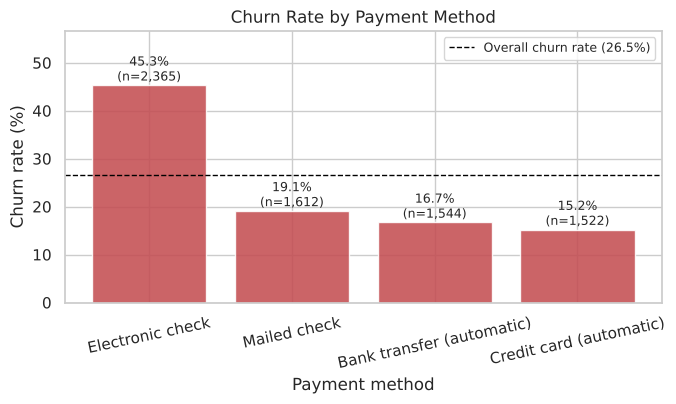

In [18]:
churn_rate_bar("PaymentMethod", "Churn Rate by Payment Method", None, "Payment method", "05_churn_by_payment_method", rotate=12)

**Interpretation.** Electronic-check customers churn at **45.3%**, 2.4–3× the rate of every other method (15.2% credit card, 16.7% bank transfer, 19.1% mailed check). **Business insight:** the two *automatic* payment methods have the lowest churn. Electronic check may be a **marker** of customers who are less committed or less engaged rather than a cause of churn; we cannot tell which from this data.

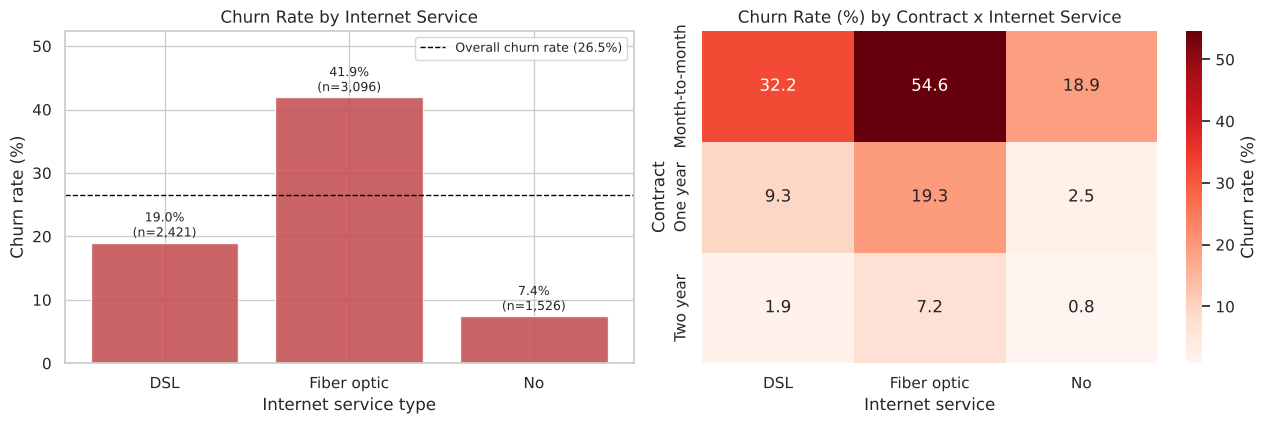

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
churn_rate_bar("InternetService", "Churn Rate by Internet Service", ["DSL", "Fiber optic", "No"], "Internet service type", ax=ax[0])
sns.heatmap(ct, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=ax[1])
ax[1].set_title("Churn Rate (%) by Contract x Internet Service"); ax[1].set_xlabel("Internet service"); ax[1].set_ylabel("Contract")
save_fig("06_churn_by_internet_service")

**Interpretation.** Fiber optic customers churn at **41.9%** vs 19.0% (DSL) and 7.4% (no internet). The heatmap confirms the effect persists *within* each contract type, and peaks at **54.6%** for month-to-month fiber customers. **Business insight:** fiber is the company's premium product yet has the worst retention — worth investigating price, reliability and competitor offers (needs data not in this file).

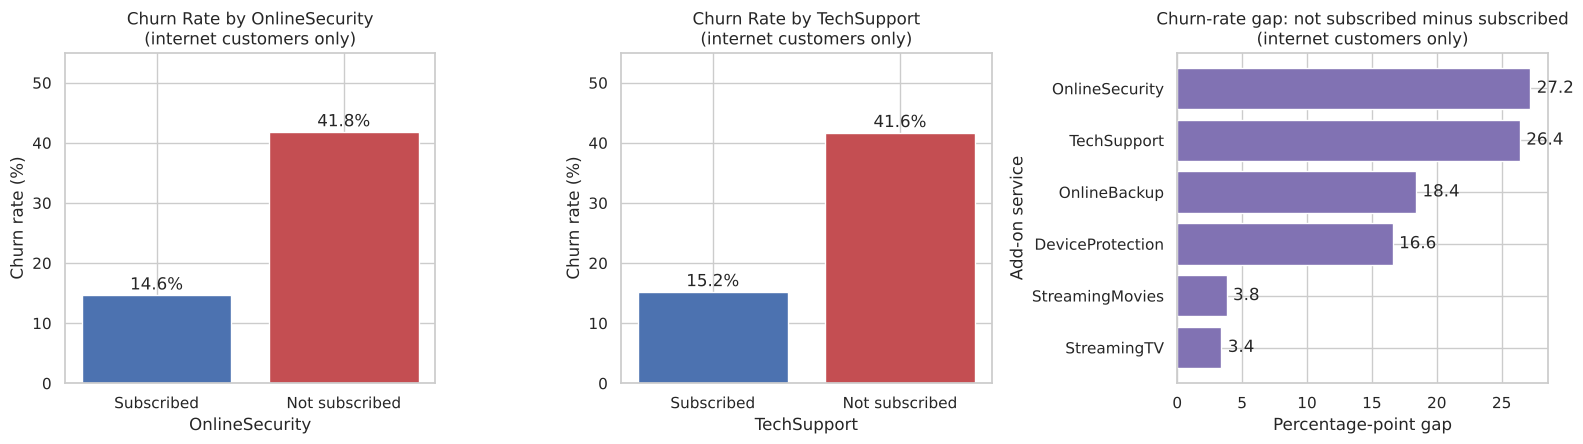

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ia = df[df.InternetService != "No"]
for a, c in zip(axes[:2], ["OnlineSecurity", "TechSupport"]):
    t = ia.groupby(c)["Churn_flag"].mean().mul(100).reindex(["Yes", "No"])
    bars = a.bar(["Subscribed", "Not subscribed"], t.values, color=["#4C72B0", "#C44E52"])
    for b, v in zip(bars, t.values): a.text(b.get_x()+b.get_width()/2, v+1, f"{v:.1f}%", ha="center")
    a.set_title(f"Churn Rate by {c}\n(internet customers only)"); a.set_ylabel("Churn rate (%)"); a.set_xlabel(c); a.set_ylim(0, 55)
g = svc["gap_pts (No - Yes)"].sort_values()
axes[2].barh(g.index, g.values, color="#8172B3"); axes[2].set_title("Churn-rate gap: not subscribed minus subscribed\n(internet customers only)")
axes[2].set_xlabel("Percentage-point gap"); axes[2].set_ylabel("Add-on service")
for i, v in enumerate(g.values): axes[2].text(v+.5, i, f"{v:.1f}", va="center")
save_fig("07_churn_by_services")

**Interpretation.** Among internet customers, those *without* Online Security churn at 41.8% vs 14.6% with it; Tech Support shows 41.6% vs 15.2%. Online Backup (39.9% vs 21.5%) and Device Protection (39.1% vs 22.5%) show smaller but still large gaps; Streaming TV/Movies show only **3–4 point gaps** (about 30% vs 34%). **Business insight:** protective/support services are associated with much lower churn, entertainment add-ons are not. Customers who take security/support may simply be more engaged, so bundling them for free would need testing before assuming it works.

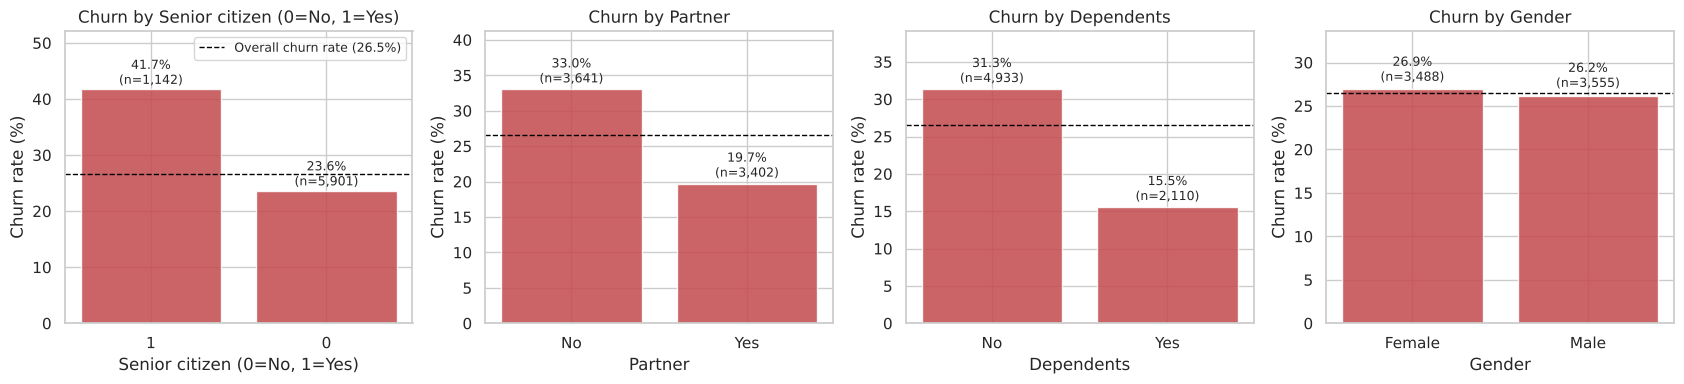

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for a, (c, t) in zip(axes, [("SeniorCitizen", "Senior citizen (0=No, 1=Yes)"), ("Partner", "Partner"), ("Dependents", "Dependents"), ("gender", "Gender")]):
    churn_rate_bar(c, f"Churn by {t}", None, t, ax=a)
    a.legend().remove() if a is not axes[0] else None
save_fig("08_churn_by_demographics")

**Interpretation.** Seniors churn at 41.7% (vs 23.6%); customers without partners or dependents churn roughly twice as often as those with them; **gender makes no meaningful difference** (26.9% vs 26.2%). **Business insight:** retention effort should be organised by lifecycle/household situation and contract, not gender. Seniors are 16% of customers but a high-risk group — handle with care for fairness and communication style.

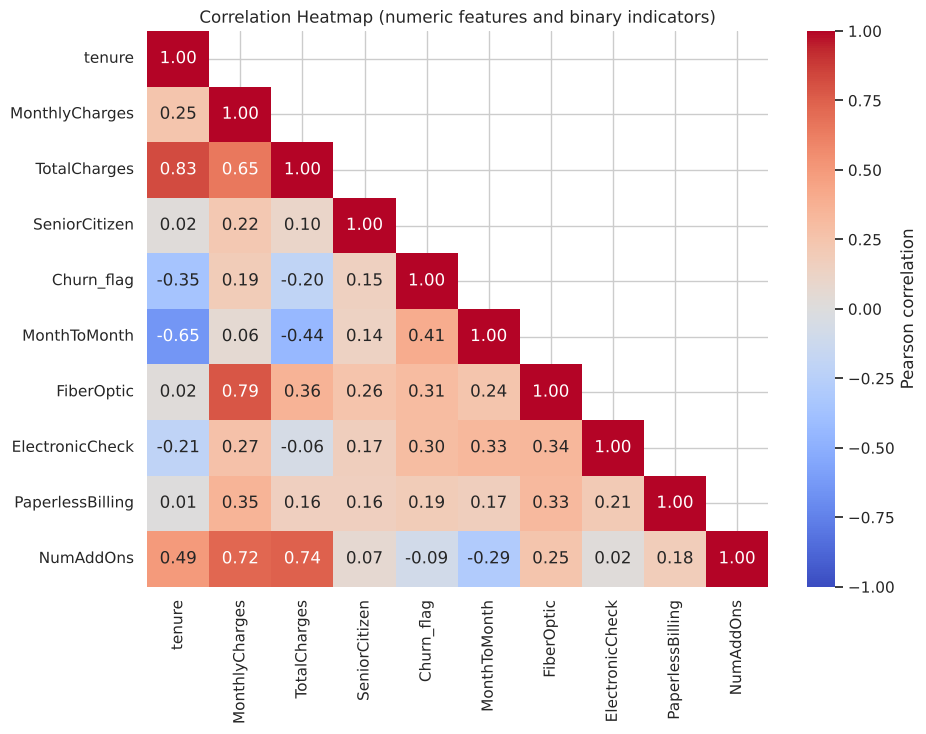

tenure             -0.35
TotalCharges       -0.20
NumAddOns          -0.09
SeniorCitizen       0.15
PaperlessBilling    0.19
MonthlyCharges      0.19
ElectronicCheck     0.30
FiberOptic          0.31
MonthToMonth        0.41
Name: Churn_flag, dtype: float64


In [22]:
corr_df = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn_flag"]].copy()
corr_df["MonthToMonth"] = (df.Contract == "Month-to-month").astype(int)
corr_df["FiberOptic"] = (df.InternetService == "Fiber optic").astype(int)
corr_df["ElectronicCheck"] = (df.PaymentMethod == "Electronic check").astype(int)
corr_df["PaperlessBilling"] = (df.PaperlessBilling == "Yes").astype(int)
corr_df["NumAddOns"] = cu.add_features(df)["NumAddOns"]
corr = corr_df.corr()
fig, ax = plt.subplots(figsize=(9.5, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation Heatmap (numeric features and binary indicators)")
save_fig("09_correlation_heatmap")
print(corr["Churn_flag"].drop("Churn_flag").sort_values().round(2))

**Interpretation.** Strongest linear correlations with churn: **tenure (−0.35)**, **month-to-month contract (+0.41)**, **electronic check (+0.30)**, fiber optic (+0.31), paperless billing (+0.19). `TotalCharges` correlates strongly with `tenure` (≈ 0.83) because it is largely *tenure × price* — the two carry overlapping information (collinearity), which matters when reading linear-model coefficients. **Business insight:** the same handful of factors — contract, tenure, payment method, service type — keep reappearing. Pearson correlation on binary indicators is a rough screening tool; it measures linear association only, not cause.

---
## Phase 5 — Feature Engineering & Preprocessing
**Purpose:** turn the cleaned data into model-ready inputs *without leaking information from the test set*.

Decisions:
1. **Drop `customerID`** (a unique label, no predictive meaning) and separate the target `Churn` → 1/0.
2. **Engineered feature `NumAddOns`:** count of the six internet add-on services subscribed — a simple, target-free summary of engagement.
3. **Encoding:** one-hot encode categoricals (`handle_unknown="ignore"` for safety on future data).
4. **Scaling:** standardise numeric features (needed by Logistic Regression, KNN and SVM; harmless for trees).
5. **Stratified 80/20 split** with a fixed seed, so every model sees the *same* train/test rows and class proportions are preserved.
6. **Leakage prevention:** the scaler/encoder are fitted **inside a `Pipeline`**, so during cross-validation they are re-fitted on each training fold only. The test set is untouched until final evaluation.
7. **Class imbalance (26.5% positive):** moderate, not extreme. We use `class_weight="balanced"` where supported (LR, Tree, Forest, SVM) rather than oversampling (which can create duplicates that leak across CV folds). KNN and Gradient Boosting in scikit-learn have no class-weight option; they are compared by threshold-independent ROC-AUC and examined at an adjusted threshold in Phase 7.

In [23]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline

model_df = cu.add_features(df)
y = model_df["Churn_flag"]
X = model_df.drop(columns=["customerID", "Churn", "Churn_flag", "TenureGroup"])   # TenureGroup is EDA-only (derived from tenure)
num_cols, cat_cols = cu.split_columns(X)
print("Features:", X.shape[1], "| numeric:", num_cols, "\n categorical:", cat_cols)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=cu.RANDOM_STATE)
print(f"\nTrain {X_train.shape} (churn {y_train.mean():.2%}) | Test {X_test.shape} (churn {y_test.mean():.2%})")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=cu.RANDOM_STATE)
preprocessor = cu.build_preprocessor(num_cols, cat_cols)
print("Encoded feature count:", preprocessor.fit(X_train).get_feature_names_out().shape[0])

Features: 20 | numeric: ['tenure', 'MonthlyCharges', 'TotalCharges', 'NumAddOns'] 
 categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Train (5634, 20) (churn 26.54%) | Test (1409, 20) (churn 26.54%)
Encoded feature count: 41


**Finding.** 5,634 training and 1,409 test customers with identical churn proportions (26.5%) in each — confirming the stratified split worked.

---
## Phase 6 — Machine Learning Modeling
**Purpose:** train the six requested algorithms under identical conditions and compare them fairly.

Method:
- A **DummyClassifier baseline** (always predicts the majority class) shows what "no skill" looks like.
- Each model is a `Pipeline(preprocessor → classifier)`; hyperparameters are tuned with **5-fold stratified `GridSearchCV` scored on ROC-AUC** (threshold-independent, suitable for imbalanced data) using the **training set only**.
- Small, regularisation-focused grids guard against overfitting. We compare **cross-validated AUC vs train AUC** to detect it.

In [24]:
import time
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score

RS = cu.RANDOM_STATE
candidates = {
    "Logistic Regression": (LogisticRegression(max_iter=3000, class_weight="balanced"), {"clf__C": [0.01, 0.1, 1, 10, 100]}),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=RS),
                      {"clf__max_depth": [3, 5, 7], "clf__min_samples_leaf": [20, 50, 100]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=RS, n_jobs=-1),
                      {"clf__n_estimators": [300], "clf__max_depth": [6, 10, None], "clf__min_samples_leaf": [5, 20]}),
    "KNN": (KNeighborsClassifier(), {"clf__n_neighbors": [15, 31, 61, 91], "clf__weights": ["uniform", "distance"]}),
    "SVM (RBF)": (SVC(probability=True, class_weight="balanced", random_state=RS), {"clf__C": [0.1, 1], "clf__gamma": ["scale", 0.01]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RS),
                          {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3]}),
}

fitted, tuning_rows = {}, []
for name, (est, grid) in candidates.items():
    t0 = time.time()
    pipe = Pipeline([("prep", cu.build_preprocessor(num_cols, cat_cols)), ("clf", est)])
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True).fit(X_train, y_train)
    fitted[name] = gs.best_estimator_
    i = gs.best_index_
    tuning_rows.append({"Model": name, "Best params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
                        "CV AUC (mean)": gs.cv_results_["mean_test_score"][i], "CV AUC (std)": gs.cv_results_["std_test_score"][i],
                        "Train AUC": roc_auc_score(y_train, gs.best_estimator_.predict_proba(X_train)[:, 1]),
                        "Fit time (s)": time.time() - t0})
    print(f"{name:20s} done in {time.time()-t0:5.1f}s  CV AUC={gs.best_score_:.4f}")

baseline = Pipeline([("prep", cu.build_preprocessor(num_cols, cat_cols)), ("clf", DummyClassifier(strategy="prior"))]).fit(X_train, y_train)
tuning = pd.DataFrame(tuning_rows).set_index("Model")
display(tuning.round(4))

Logistic Regression  done in   2.0s  CV AUC=0.8462


Decision Tree        done in   2.9s  CV AUC=0.8332


Random Forest        done in  30.8s  CV AUC=0.8481


KNN                  done in   3.8s  CV AUC=0.8373


SVM (RBF)            done in  69.3s  CV AUC=0.8422


Gradient Boosting    done in  35.5s  CV AUC=0.8499


,Best params,CV AUC (mean),CV AUC (std),Train AUC,Fit time (s)
Model,,,,,
Logistic Regression,{'C': 10},0.8462,0.0127,0.8495,1.9511
Decision Tree,"{'max_depth': 7, 'min_samples_leaf': 100}",0.8332,0.0125,0.8544,2.9269
Random Forest,"{'max_depth': 10, 'min_samples_leaf': 20, 'n_e...",0.8481,0.0099,0.8786,30.7826
KNN,"{'n_neighbors': 91, 'weights': 'uniform'}",0.8373,0.0115,0.8458,3.8189
SVM (RBF),"{'C': 1, 'gamma': 0.01}",0.8422,0.0105,0.8479,69.3485
Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 2, 'n_est...",0.8499,0.0121,0.8638,35.5330


**How to read this table.** `CV AUC` is the average ROC-AUC across the five validation folds (what the model achieves on data it was *not* trained on); `std` shows fold-to-fold noise. A large gap between `Train AUC` and `CV AUC` signals overfitting.

In [25]:
tuning["Overfit gap (Train - CV)"] = tuning["Train AUC"] - tuning["CV AUC (mean)"]
display(tuning[["CV AUC (mean)", "CV AUC (std)", "Train AUC", "Overfit gap (Train - CV)"]].round(4).sort_values("CV AUC (mean)", ascending=False))

,CV AUC (mean),CV AUC (std),Train AUC,Overfit gap (Train - CV)
Model,,,,
Gradient Boosting,0.8499,0.0121,0.8638,0.0139
Random Forest,0.8481,0.0099,0.8786,0.0306
Logistic Regression,0.8462,0.0127,0.8495,0.0033
SVM (RBF),0.8422,0.0105,0.8479,0.0058
KNN,0.8373,0.0115,0.8458,0.0085
Decision Tree,0.8332,0.0125,0.8544,0.0213


---
## Phase 7 — Model Evaluation
**Purpose:** judge every model on the held-out **test set** with metrics that fit the business goal.

Metric guide in plain language (churn = "positive"):
- **Recall** — of customers who really churn, what share do we catch? *Missed churners are lost revenue.*
- **Precision** — of customers we flag, what share really churn? *Low precision wastes retention budget on customers who would have stayed.*
- **F1** — a single balance of the two. **ROC-AUC** — how well the model *ranks* risky customers above safe ones, regardless of cut-off.
- **Accuracy** — shown, but **not used to select** the model (the 73.5% majority-class baseline is already "accurate").

In [26]:
probas = {n: m.predict_proba(X_test)[:, 1] for n, m in fitted.items()}
res = [cu.evaluate("Baseline (always 'No churn')", y_test, baseline.predict_proba(X_test)[:, 1])]
res += [cu.evaluate(n, y_test, p) for n, p in probas.items()]
comparison = pd.DataFrame(res).set_index("Model")
comparison.loc[tuning.index, "CV AUC"] = tuning["CV AUC (mean)"]
display(comparison.round(3).style.background_gradient(cmap="Blues", subset=["Recall", "Precision", "F1", "ROC-AUC"]))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,CV AUC
Model,,,,,,,
Baseline (always 'No churn'),0.735000,0.000000,0.000000,0.000000,0.500000,0.265000,nan
Logistic Regression,0.738000,0.504000,0.783000,0.614000,0.841000,0.627000,0.846000
Decision Tree,0.739000,0.505000,0.781000,0.613000,0.835000,0.615000,0.833000
Random Forest,0.748000,0.517000,0.791000,0.625000,0.844000,0.656000,0.848000
KNN,0.782000,0.592000,0.575000,0.583000,0.831000,0.614000,0.837000
SVM (RBF),0.787000,0.594000,0.626000,0.609000,0.834000,0.631000,0.842000
Gradient Boosting,0.799000,0.660000,0.503000,0.571000,0.846000,0.664000,0.850000


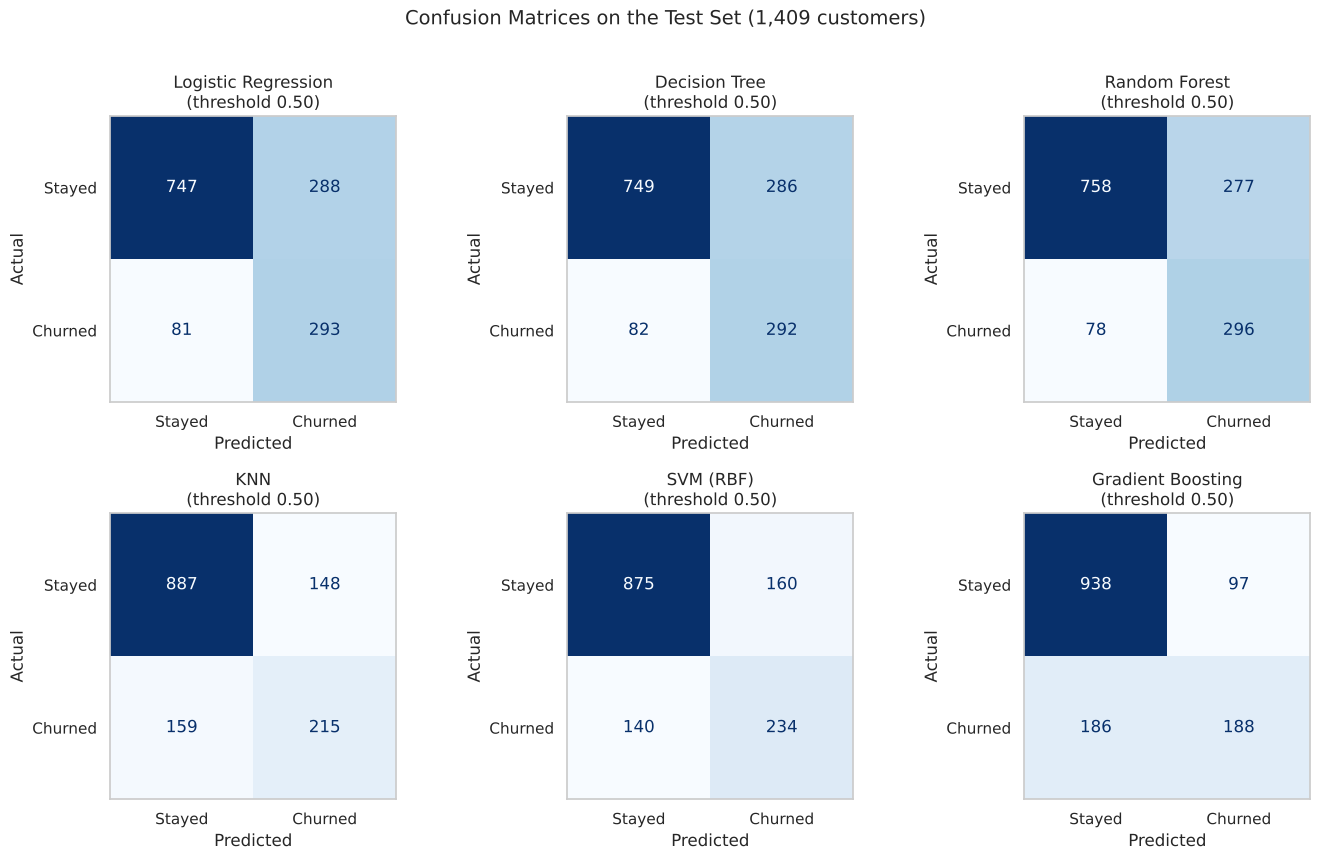

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_curve, precision_recall_curve, confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for a, (n, p) in zip(axes.ravel(), probas.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (p >= .5).astype(int), display_labels=["Stayed", "Churned"], cmap="Blues", colorbar=False, ax=a)
    a.set_title(f"{n}\n(threshold 0.50)"); a.set_xlabel("Predicted"); a.set_ylabel("Actual"); a.grid(False)
plt.suptitle("Confusion Matrices on the Test Set (1,409 customers)", fontsize=14, y=1.01)
save_fig("10_confusion_matrices")

In [28]:
for n, p in probas.items():
    print("="*70, f"\n{n}"); print(classification_report(y_test, (p >= .5).astype(int), target_names=["Stayed", "Churned"], digits=3))

Logistic Regression
              precision    recall  f1-score   support

      Stayed      0.902     0.722     0.802      1035
     Churned      0.504     0.783     0.614       374

    accuracy                          0.738      1409
   macro avg      0.703     0.753     0.708      1409
weighted avg      0.797     0.738     0.752      1409

Decision Tree
              precision    recall  f1-score   support

      Stayed      0.901     0.724     0.803      1035
     Churned      0.505     0.781     0.613       374

    accuracy                          0.739      1409
   macro avg      0.703     0.752     0.708      1409
weighted avg      0.796     0.739     0.753      1409

Random Forest
              precision    recall  f1-score   support

      Stayed      0.907     0.732     0.810      1035
     Churned      0.517     0.791     0.625       374

    accuracy                          0.748      1409
   macro avg      0.712     0.762     0.718      1409
weighted avg      0.803   

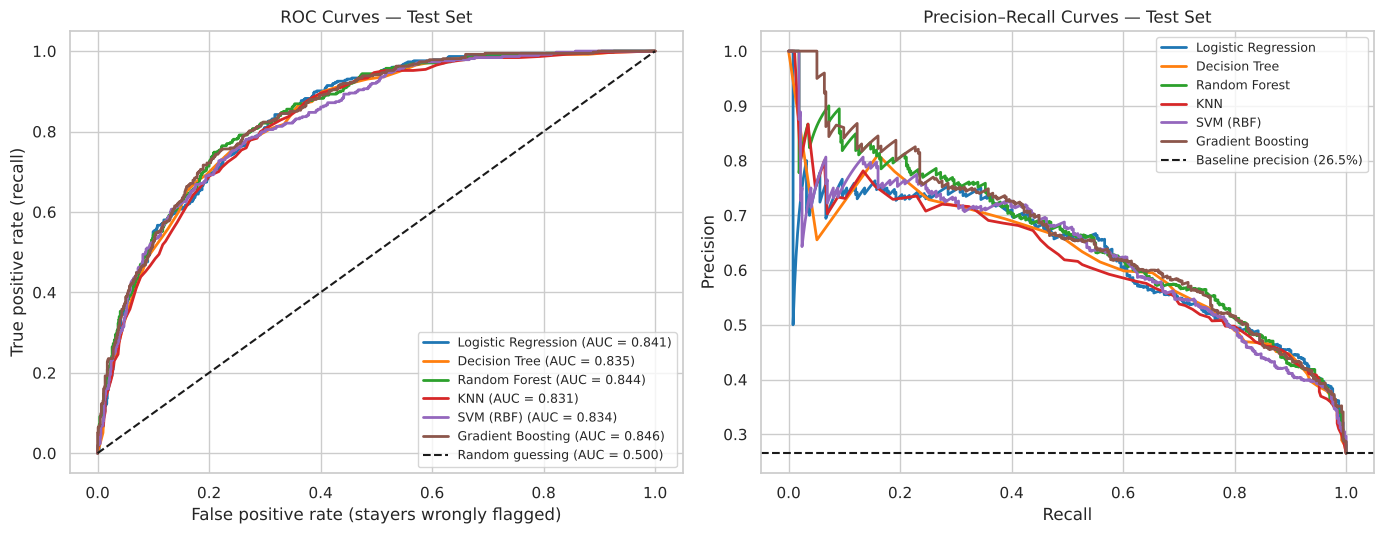

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
colors = sns.color_palette("tab10", len(probas))
for (n, p), c in zip(probas.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, color=c, lw=2, label=f"{n} (AUC = {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); ax[1].plot(rc, pr, color=c, lw=2, label=n)
ax[0].plot([0, 1], [0, 1], "k--", label="Random guessing (AUC = 0.500)")
ax[0].set_title("ROC Curves — Test Set"); ax[0].set_xlabel("False positive rate (stayers wrongly flagged)"); ax[0].set_ylabel("True positive rate (recall)"); ax[0].legend(loc="lower right", fontsize=9)
ax[1].axhline(y_test.mean(), color="k", ls="--", label=f"Baseline precision ({y_test.mean():.1%})")
ax[1].set_title("Precision–Recall Curves — Test Set"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend(loc="upper right", fontsize=9)
save_fig("11_roc_and_pr_curves")

### Model comparison and selection

**What the numbers show** (test set, probability threshold 0.50; table above):

| Model | Test ROC-AUC | CV ROC-AUC (±std) | Recall | Precision | Accuracy |
|---|---|---|---|---|---|
| Gradient Boosting | 0.846 | 0.850 (±0.012) | 0.503 | 0.660 | 0.799 |
| Random Forest | 0.844 | 0.848 (±0.010) | 0.791 | 0.517 | 0.748 |
| **Logistic Regression** | 0.841 | 0.846 (±0.013) | 0.783 | 0.504 | 0.738 |
| Decision Tree | 0.836 | 0.833 (±0.013) | 0.781 | 0.505 | 0.739 |
| SVM (RBF) | 0.834 | 0.842 (±0.011) | 0.626 | 0.594 | 0.787 |
| KNN | 0.831 | 0.837 (±0.012) | 0.575 | 0.592 | 0.782 |
| Baseline | 0.500 | – | 0.000 | – | 0.735 |

1. **All six models clearly beat the baseline** (AUC 0.83–0.85 vs 0.50), so churn is genuinely predictable from these attributes — but not perfectly.
2. **The top three on ranking quality are statistically indistinguishable.** The gap between Gradient Boosting and Logistic Regression is 0.004 (CV) — smaller than the fold-to-fold standard deviation (about 0.01–0.013). Picking the "winner" on that margin would be over-reading noise.
3. **Accuracy is misleading here.** The three models with the highest accuracy (Gradient Boosting 0.799, SVM 0.787, KNN 0.782) are the ones that *miss the most churners* (recall 0.50–0.63). Part of this is a threshold effect, not model quality: LR, Tree and Forest use `class_weight="balanced"` and so flag more customers at 0.50, while Gradient Boosting and KNN do not. This is why we compare ranking metrics (ROC-AUC, PR-AUC) and then tune the threshold separately.
4. **Overfitting check.** Random Forest shows the largest train-vs-CV gap (0.031); Logistic Regression the smallest (0.003).

**Decision: Logistic Regression is selected as the final model**, because
- its ranking performance is statistically tied with the best models (CV AUC 0.846 vs 0.850),
- it generalises most stably (smallest overfitting gap) and trains in about 1 second vs 26–31 s for the forest/boosting search,
- it is transparent and auditable — important when the output drives customer-facing retention decisions,
- at the default threshold it already catches 78% of churners.

**Honest trade-off:** Gradient Boosting and Random Forest have slightly higher PR-AUC on this test set (0.664 and 0.656 vs 0.627), which matters if the client mainly cares about precision among the very top-ranked customers. With only 374 churners in the test set this difference is not conclusive; we recommend re-testing on newer data before committing to a more complex model. Decision Tree, KNN and SVM are not preferred (lower AUC; SVM is slowest; KNN's best `k` was the largest value in the grid, 91, so a wider search could change its score slightly).

In [30]:
# Save the comparison table
out = comparison.round(4).copy(); out.index.name = "Model"
out.to_csv(ROOT / "outputs" / "model_comparison.csv")
print("Saved outputs/model_comparison.csv")

Saved outputs/model_comparison.csv


### Threshold selection for the chosen model
A model outputs a *probability*; the business decides the *cut-off* for "high risk". The default 0.50 is arbitrary. Lowering it catches more churners (higher recall) but flags more stayers (lower precision). **To avoid peeking at the test set, we choose the threshold using out-of-fold predictions on the training data only**, then evaluate that single choice once on the test set.

Assumption (to be confirmed with the client): missing a churner costs more than a wasted retention offer, so we select the threshold that maximises **F2** (recall weighted twice as much as precision).

,precision,recall,F1,F2,share_flagged
threshold,,,,,
0.20,0.386,0.953,0.549,0.737,0.655
0.25,0.404,0.937,0.565,0.742,0.615
0.30,0.424,0.926,0.582,0.749,0.579
0.35,0.447,0.903,0.598,0.750,0.536
0.40,0.470,0.870,0.610,0.743,0.491
0.45,0.492,0.833,0.618,0.731,0.450
0.50,0.516,0.800,0.627,0.721,0.411
0.55,0.541,0.766,0.634,0.707,0.376
0.60,0.570,0.719,0.636,0.683,0.335


Chosen threshold (max F2 on out-of-fold training predictions): 0.35


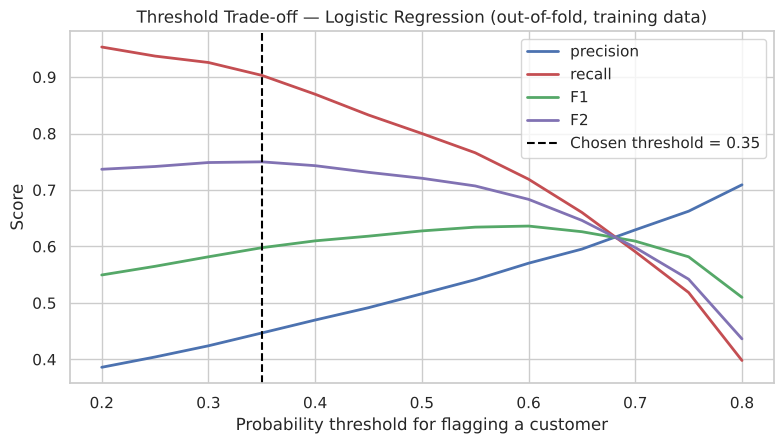

In [31]:
from sklearn.metrics import fbeta_score, precision_score, recall_score
FINAL_NAME = "Logistic Regression"
final_model = fitted[FINAL_NAME]
oof = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

grid_t = np.round(np.arange(0.20, 0.81, 0.05), 2)
thr = pd.DataFrame({"threshold": grid_t,
                    "precision": [precision_score(y_train, oof >= t) for t in grid_t],
                    "recall": [recall_score(y_train, oof >= t) for t in grid_t],
                    "F1": [fbeta_score(y_train, oof >= t, beta=1) for t in grid_t],
                    "F2": [fbeta_score(y_train, oof >= t, beta=2) for t in grid_t],
                    "share_flagged": [(oof >= t).mean() for t in grid_t]}).set_index("threshold")
best_t = float(thr["F2"].idxmax())
display(thr.round(3))
print(f"Chosen threshold (max F2 on out-of-fold training predictions): {best_t}")

fig, ax = plt.subplots(figsize=(8, 4.6))
for c, col in zip(["precision", "recall", "F1", "F2"], ["#4C72B0", "#C44E52", "#55A868", "#8172B3"]): ax.plot(thr.index, thr[c], label=c, color=col, lw=2)
ax.axvline(best_t, color="black", ls="--", label=f"Chosen threshold = {best_t}")
ax.set_title(f"Threshold Trade-off — {FINAL_NAME} (out-of-fold, training data)"); ax.set_xlabel("Probability threshold for flagging a customer"); ax.set_ylabel("Score"); ax.legend()
save_fig("12_threshold_tradeoff")

In [32]:
p_final = probas[FINAL_NAME]
for t, label in [(0.5, "default 0.50"), (best_t, f"chosen {best_t}")]:
    pred = (p_final >= t).astype(int); tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"[{label}] flagged {pred.mean():.1%} of customers | precision {precision_score(y_test, pred):.3f} | recall {recall_score(y_test, pred):.3f} "
          f"| F1 {fbeta_score(y_test, pred, beta=1):.3f} | TP {tp}  FP {fp}  FN {fn}  TN {tn}")

# Lift: how many churners do we reach by contacting only the riskiest X% of customers?
order = np.argsort(-p_final); y_sorted = y_test.values[order]
lift = pd.DataFrame({"contact top %": [10, 20, 30, 40, 50]})
lift["customers contacted"] = (lift["contact top %"] / 100 * len(y_test)).round().astype(int)
lift["% of all churners reached"] = [round(y_sorted[:k].sum() / y_sorted.sum() * 100, 1) for k in lift["customers contacted"]]
lift["precision in group %"] = [round(y_sorted[:k].mean() * 100, 1) for k in lift["customers contacted"]]
display(lift)

[default 0.50] flagged 41.2% of customers | precision 0.504 | recall 0.783 | F1 0.614 | TP 293  FP 288  FN 81  TN 747
[chosen 0.35] flagged 53.8% of customers | precision 0.445 | recall 0.901 | F1 0.595 | TP 337  FP 421  FN 37  TN 614


,contact top %,customers contacted,% of all churners reached,precision in group %
0,10,141,28.3,75.2
1,20,282,50.0,66.3
2,30,423,64.4,57.0
3,40,564,77.3,51.2
4,50,704,87.2,46.3


**Findings.**
- On out-of-fold training predictions F2 is highest at threshold **0.35** (F2 0.750), but the curve is flat between 0.30 and 0.40, so the choice is not sharp.
- On the untouched test set, moving from 0.50 to 0.35 raises recall from **0.783 to 0.901** (churners caught: 293 → 337 of 374; missed: 81 → 37) at the cost of precision (**0.504 → 0.445**) and 133 extra false alarms (288 → 421). F1 falls slightly (0.614 → 0.595). The test results mirror the out-of-fold ones (recall 0.903, precision 0.447), which suggests the threshold was not over-fitted.
- **Operational reality:** at 0.35, **53.8% of customers are flagged**. That is likely too many for a costly offer. The lift table is the more practical guide: contacting only the **riskiest 20%** of customers reaches **50% of all churners with 66% precision**; the riskiest 30% reaches 64%.

**Recommendation:** use the model to *rank* customers and tier the response — a high-touch tier for the top ~20%, and a cheap automated tier (e.g. an email offer) down to the 0.35 threshold. The final cut-off should be set from the cost of an offer versus the value of a retained customer, which this dataset does not contain; 0.35 is a documented starting assumption, not a verified optimum.

---
## Phase 8 — Model Interpretation
**Purpose:** understand *what the model uses* and explain it to non-technical stakeholders. Importance describes the model's behaviour, **not causal effects**.

Two complementary views of the chosen model:
1. **Permutation importance** (on the test set, original features): shuffle one feature at a time and measure how much the ROC-AUC drops. Works for any model and treats a categorical feature as a single unit.
2. **Logistic-regression coefficients** (direction and relative size, in standardised/encoded units): positive = higher modelled churn risk, holding other features constant.

,feature,AUC drop,std
4,tenure,0.1617,0.0079
17,MonthlyCharges,0.1277,0.0103
7,InternetService,0.1263,0.0100
14,Contract,0.0411,0.0043
19,NumAddOns,0.0262,0.0043
18,TotalCharges,0.0136,0.0032
6,MultipleLines,0.0121,0.0028
8,OnlineSecurity,0.0102,0.0025
13,StreamingMovies,0.0100,0.0025
12,StreamingTV,0.0094,0.0037


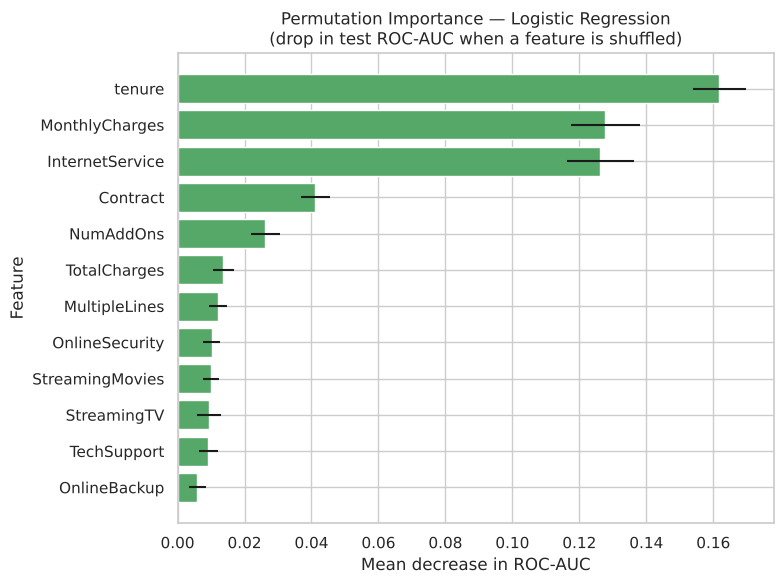

In [33]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=RS, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "AUC drop": pi.importances_mean, "std": pi.importances_std}).sort_values("AUC drop", ascending=False)
display(imp.head(12).round(4))
fig, ax = plt.subplots(figsize=(8, 6))
top = imp.head(12).iloc[::-1]
ax.barh(top["feature"], top["AUC drop"], xerr=top["std"], color="#55A868")
ax.set_title(f"Permutation Importance — {FINAL_NAME}\n(drop in test ROC-AUC when a feature is shuffled)"); ax.set_xlabel("Mean decrease in ROC-AUC"); ax.set_ylabel("Feature")
save_fig("13_permutation_importance")

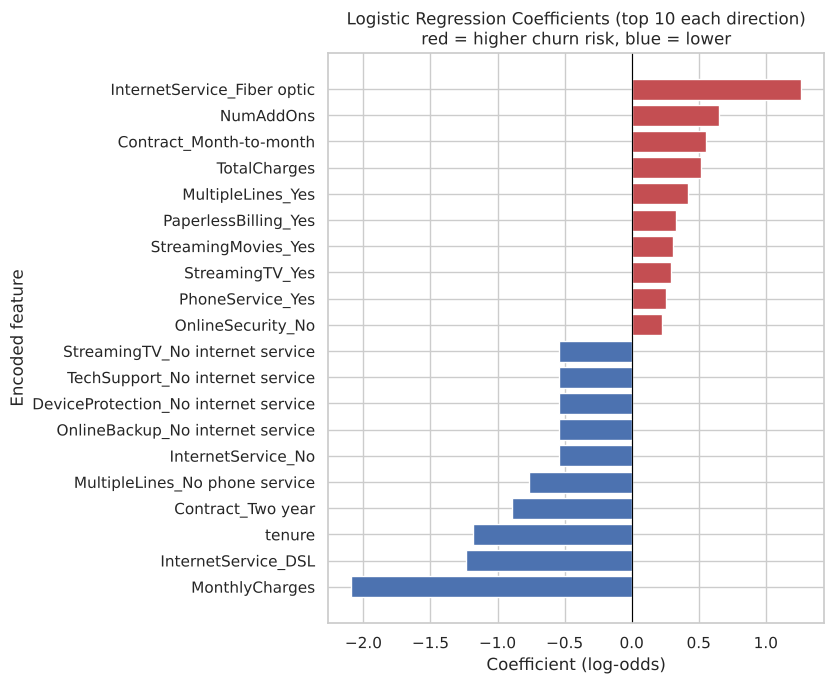

,coef
MonthlyCharges,-2.093
InternetService_DSL,-1.236
tenure,-1.181
Contract_Two year,-0.892
MultipleLines_No phone service,-0.764
InternetService_No,-0.539
OnlineBackup_No internet service,-0.539
DeviceProtection_No internet service,-0.539
TechSupport_No internet service,-0.539
StreamingTV_No internet service,-0.539


In [34]:
lr_pipe = fitted["Logistic Regression"]
names = lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_pipe.named_steps["clf"].coef_[0], index=[n.split("__")[1] for n in names]).sort_values()
sel = pd.concat([coefs.head(10), coefs.tail(10)])
fig, ax = plt.subplots(figsize=(8.5, 7))
ax.barh(sel.index, sel.values, color=["#4C72B0" if v < 0 else "#C44E52" for v in sel.values])
ax.axvline(0, color="black", lw=.8)
ax.set_title("Logistic Regression Coefficients (top 10 each direction)\nred = higher churn risk, blue = lower"); ax.set_xlabel("Coefficient (log-odds)"); ax.set_ylabel("Encoded feature")
save_fig("14_logistic_coefficients")
display(sel.round(3).to_frame("coef"))

### What drives churn risk in the model

**Permutation importance (the most reliable view here)**
- **Top three: `tenure` (AUC drop 0.162), `MonthlyCharges` (0.128), `InternetService` (0.126).** Next: `Contract` (0.041), `NumAddOns` (0.026) and `TotalCharges` (0.014). Every other feature contributes 0.012 or less.
- **Demographics (gender, partner, dependents) and payment method do not appear in the top 12.** Their raw associations with churn (e.g. electronic check 45.3%) are largely *already captured* by contract, tenure and service type; payment method looks more like a marker of risky customers than an independent driver (an inference from the model, not a proven fact).
- Correlated features share credit (tenure/TotalCharges; MonthlyCharges/InternetService/add-ons), so each one's individual importance is understated.

**Logistic-regression coefficients — read with care**
- Directions that agree with the EDA and are stable: **fiber optic raises risk (+1.27)**, DSL (−1.24) and no-internet (−0.54) lower it; **longer tenure lowers risk (−1.18 per standard deviation)**; **two-year contracts lower risk (−0.89)** and month-to-month raises it (+0.56).
- **Some coefficients look contradictory and should NOT be interpreted individually:** `MonthlyCharges` is negative (−2.09) and `NumAddOns` positive (+0.65), the opposite of the simple EDA patterns. This is *multicollinearity*: monthly price is almost fully determined by the service choices (fiber, add-ons), so the model splits and offsets their effects. It does not mean "higher prices reduce churn".

### Plain-language explanation for non-technical stakeholders
The model has learned that customers are most likely to leave when they are **new** (especially in their first year), on a **month-to-month contract**, on the **fiber optic** service, **paying higher monthly bills**, and **without security or tech-support add-ons**. Customers who have been with the company for years, hold one- or two-year contracts, or use DSL are much less likely to leave. The model gives each customer a risk score; it ranks people well (about 0.84 on a 0–1 scale where 0.5 is a coin flip) but is not a crystal ball — at the default setting, roughly half the customers it flags would have stayed anyway.

### Limitations
1. **Associations, not causes.** Nothing here shows that changing a contract, price or add-on *would* change behaviour. Customers who choose long contracts or take support services may already differ in loyalty.
2. **Snapshot without dates.** The file has no timestamps, so we cannot confirm that every feature was known *before* a customer left. In particular, a churner's `tenure` stops at the moment they leave, so part of the "short tenure → churn" signal is built into how the data was recorded. Performance on a live "who will leave next month" task may be lower than shown here.
3. **Missing drivers.** There are no reasons for leaving, usage, complaints, call-centre contacts, competitor prices or offer history — the factors most likely to explain *why* fiber customers leave.
4. **Single sample, single split.** 1,409 test customers (374 churners). Model differences of ~0.01 AUC are within noise. Results may not carry to today's customers.
5. **Probabilities are not calibrated.** Because class weights were used, a score of 0.6 does not mean a 60% chance of churning; use scores for *ranking* and threshold-setting.
6. **Fairness not audited.** `SeniorCitizen` and `gender` are inputs; seniors are a high-churn group (41.7%). Before deployment, review whether using such attributes is appropriate and test for unequal error rates.
7. **Not an automatic decision-maker.** The model supports human retention decisions.

---
## Phase 9 — Business Insights & Recommendations
Segment sizes and revenue figures below are computed from the dataset (monthly recurring revenue = sum of `MonthlyCharges`).

In [35]:
def seg_stats(mask, label):
    s = df[mask]; 
    return {"Segment": label, "Customers": len(s), "% of base": round(len(s)/len(df)*100, 1), "Churn rate %": round(s.Churn_flag.mean()*100, 1),
            "Churned customers": int(s.Churn_flag.sum()), "% of all churners": round(s.Churn_flag.sum()/df.Churn_flag.sum()*100, 1),
            "Monthly $ lost (churned)": round(s.loc[s.Churn_flag==1, "MonthlyCharges"].sum())}
internet = df.InternetService != "No"
segs = [seg_stats(df.Contract == "Month-to-month", "Month-to-month contract"),
        seg_stats((df.Contract == "Month-to-month") & (df.tenure <= 12), "Month-to-month, first 12 months"),
        seg_stats((df.Contract == "Month-to-month") & (df.InternetService == "Fiber optic"), "Month-to-month + Fiber"),
        seg_stats(df.PaymentMethod == "Electronic check", "Electronic check payers"),
        seg_stats(internet & (df.OnlineSecurity == "No") & (df.TechSupport == "No"), "Internet, no Security & no Tech Support"),
        seg_stats((df.Contract == "Month-to-month") & (df.PaymentMethod == "Electronic check") & (df.InternetService == "Fiber optic"), "M2M + E-check + Fiber"),
        seg_stats((df.Contract != "Month-to-month") & (df.PaymentMethod.str.contains("automatic")), "Annual/2-yr + auto-pay (low-risk reference)")]
seg_df = pd.DataFrame(segs).set_index("Segment"); display(seg_df)
print(f"Total monthly $ of churned customers: ${df.loc[df.Churn_flag==1,'MonthlyCharges'].sum():,.0f}")

# Do month-to-month customers get cheaper-or-pricier plans?  (context for pricing discussion)
display(df.groupby("Contract")["MonthlyCharges"].agg(["mean", "median"]).round(1))
# Add-on count vs churn among internet customers
display(cu.add_features(df[internet]).groupby("NumAddOns")["Churn_flag"].agg(["mean", "size"]).assign(mean=lambda d: (d["mean"]*100).round(1)).rename(columns={"mean": "churn_rate_%", "size": "customers"}))

,Customers,% of base,Churn rate %,Churned customers,% of all churners,Monthly $ lost (churned)
Segment,,,,,,
Month-to-month contract,3875,55.0,42.7,1655,88.6,120847
"Month-to-month, first 12 months",1994,28.3,51.4,1024,54.8,68301
Month-to-month + Fiber,2128,30.2,54.6,1162,62.2,100482
Electronic check payers,2365,33.6,45.3,1071,57.3,84289
"Internet, no Security & no Tech Support",2553,36.2,49.0,1250,66.9,95153
M2M + E-check + Fiber,1307,18.6,60.4,789,42.2,68282
Annual/2-yr + auto-pay (low-risk reference),1934,27.5,5.7,111,5.9,9551


Total monthly $ of churned customers: $139,131


,mean,median
Contract,,
Month-to-month,66.4,73.2
One year,65.0,68.8
Two year,60.8,64.4


,churn_rate_%,customers
NumAddOns,,
0,52.2,693
1,45.8,966
2,35.8,1033
3,27.4,1118
4,22.3,852
5,12.4,571
6,5.3,284


### Recommendations (each tied to a measured finding)

Churned customers carried **\$139,131 per month** of recurring revenue (30.5% of the monthly total in this file). We do **not** claim a specific saving from any action below — each should be piloted with a control group.

| # | Recommendation | Evidence from this dataset |
|---|---|---|
| 1 | **Focus on the first year, especially month-to-month customers.** Launch an onboarding programme (check-ins in the first 3–6 months, early-life offers). | Month-to-month customers in months 0–12: 1,994 customers (28.3% of base), **51.4% churn**, **54.8% of all churners**. Overall tenure 0–12 churn: 47.4% vs 9.5% after 48 months. |
| 2 | **Encourage moves to 1- or 2-year contracts** with a modest benefit (discount, free add-on, device credit). Pilot with a control group, because loyal customers may self-select into long contracts. | Churn: month-to-month 42.7%, one-year 11.3%, two-year 2.8%. Month-to-month = 88.6% of churners. |
| 3 | **Investigate and fix the fiber-optic proposition** (service quality, price versus competitors, exit survey) before spending on discounts. | Fiber 41.9% churn vs DSL 19.0%; gap persists within every contract type. **Month-to-month fiber: 2,128 customers, 54.6% churn, 62.2% of churners, \$100,482/month lost.** |
| 4 | **Trial security / tech-support bundles for at-risk internet customers** (e.g. 3–6 months free), measured against a control group. Do not prioritise streaming add-ons. | Without Online Security 41.8% vs 14.6% with; Tech Support 41.6% vs 15.2%. Internet customers with neither: 2,553 customers, **49.0% churn, 66.9% of churners**. Churn falls from 52.2% (0 add-ons) to 5.3% (6 add-ons). Streaming gap only 3–4 pts. |
| 5 | **Migrate electronic-check payers to automatic payment** with a small incentive, and treat electronic check as a risk flag in targeting. | Electronic check 45.3% churn (2,365 customers, 57.3% of churners) vs 15.2–16.7% for automatic methods. The model suggests payment method adds little beyond other features, so expect a smaller effect than the raw gap implies. |
| 6 | **Review pricing for high-bill, no-commitment customers** (e.g. price-lock or plan right-sizing in exchange for a contract). | Churners' median bill \$79.65 vs \$64.43; churn 37.8% in the \$70–90 band vs 9.8% at \$30 or less. Price cannot be separated from service type in this data. |
| 7 | **Run a model-guided, tiered retention campaign.** Score all active customers; high-touch contact for the top ~20% (reaches 50% of churners at 66% precision in the test set), cheap automated outreach down to the 0.35 threshold; keep a random hold-out group to measure whether offers actually *work*. | Test-set lift table; threshold analysis (recall 0.90 at 0.35). The model predicts who is *likely to leave*, not who will *respond* to an offer. |
| 8 | **Support senior customers with tailored service** (not exclusion or worse terms). | Seniors: 1,142 customers (16%), 41.7% churn vs 23.6%. Subject to fairness review. |

**Deprioritise:** gender-based campaigns (26.9% vs 26.2% — no difference) and phone-service or streaming promotions as retention levers (small gaps).

**Data that would improve the analysis:** churn dates and stated reasons, usage and network-quality data, support/complaint history, competitor pricing, prior offers and responses, customer margin and acquisition cost (to set the threshold economically), and time-stamped snapshots so the model predicts *future* churn.

---
## Phase 10 — Final Deliverables

In [36]:
joblib.dump({"pipeline": final_model, "threshold": best_t, "model_name": FINAL_NAME, "features": list(X.columns)}, MODEL_DIR / "best_model.joblib")
print("Saved:", (MODEL_DIR / "best_model.joblib").relative_to(ROOT))
for p in sorted(FIG_DIR.glob("*.png")): print(" figure:", p.name)
print("Cleaned data :", DATA_CLEAN.relative_to(ROOT)); print("Model table  :", "outputs/model_comparison.csv")
# Reproducibility: reload and verify that predictions are identical
bundle = joblib.load(MODEL_DIR / "best_model.joblib")
assert np.allclose(bundle["pipeline"].predict_proba(X_test)[:, 1], p_final)
print("Reload check passed.")

Saved: models/best_model.joblib
 figure: 01_churn_distribution.png
 figure: 02_churn_by_contract.png
 figure: 03_churn_by_tenure.png
 figure: 04_monthly_charges_vs_churn.png
 figure: 05_churn_by_payment_method.png
 figure: 06_churn_by_internet_service.png
 figure: 07_churn_by_services.png
 figure: 08_churn_by_demographics.png
 figure: 09_correlation_heatmap.png
 figure: 10_confusion_matrices.png
 figure: 11_roc_and_pr_curves.png
 figure: 12_threshold_tradeoff.png
 figure: 13_permutation_importance.png
 figure: 14_logistic_coefficients.png
 figure: outlier_boxplots.png
Cleaned data : data/processed/telco_churn_cleaned.csv
Model table  : outputs/model_comparison.csv
Reload check passed.


### Executive summary
- **Problem:** 1,869 of 7,043 customers (26.5%) churned, carrying \$139,131 of monthly revenue.
- **Where churn concentrates:** month-to-month contracts (42.7%; 88.6% of all churners), the first 12 months (47.4%), fiber optic (41.9%; 54.6% when month-to-month), electronic-check payers (45.3%), and internet customers without security/support add-ons (~42%). Two-year contracts churn at 2.8%.
- **Model:** six algorithms compared under identical splits and cross-validated tuning. All reach ROC-AUC 0.83–0.85; the top three are statistically tied. **Logistic Regression is selected** for stability, transparency and speed (test AUC 0.841, recall 0.78 at default). At a 0.35 threshold it catches 90% of churners but flags 54% of customers; the riskiest 20% contains half of all churners.
- **Cautions:** associations only; snapshot data without dates; no reasons for churn; model supports, not replaces, human decisions.
- **Next step:** pilot recommendations 1–7 with control groups.

**Files produced:** this notebook · `data/processed/telco_churn_cleaned.csv` · `outputs/visualizations/*.png` · `outputs/model_comparison.csv` · `models/best_model.joblib` · `reports/Final_Report.pdf` · `reports/Business_Recommendations.pdf` · `dashboard/app.py`